# TP3 — Transformación de Datos

**IMPORTANTE:** Al utilizar herramientas de inteligencia artificial deben indicar qué IA están usando y con qué propósito. Por ejemplo: "Claude Opus 4.6" para "mejorar redacción de textos" o "Chat GPT 5.6" para "crear código fuente".


## Introducción

En el TP1 procesaron el flujo de datos de GDELT 2.0. En el TP2 crearon un diseño de almacén de datos estructurado de forma tal que permita responder preguntas clave del negocio periodístico. Ahora, el equipo de Investigación & Ciencia de Datos de un Medio Internacional de Noticias requiere analizar el comportamiento multivariante del ecosistema global de noticias. A diferencia del conjunto de datos Iris, donde la dimensionalidad es baja y las distribuciones son homogéneas, el flujo de GDELT 2.0 es ruidoso, disperso y de alta dimensionalidad.



## Recursos

* Lista de URLs con actualizaciones cada 15 minutos https://data.gdeltproject.org/gdeltv2/masterfilelist.txt
* URL oficial del libro de códigos de GDELT 2.0 https://data.gdeltproject.org/documentation/GDELT-Event_Codebook-V2.0.pdf
* URL de la documentación en texto/HTML donde se enuncian los campos https://gdeltproject.org/data/documentation/CAMEO.Manual.1.1b3.pdf


## Requisitos y Preguntas de Investigación

El análisis multivariante debe estructurarse para responder las siguientes 4 preguntas clave del análisis mediático e inteligencia global:

- **Perfil Multivariante de eventos:** ¿Cómo se caracterizan simultáneamente los eventos mediante sus vectores de medias?
- **Topología de Cobertura Mediática:** ¿Qué perfiles de eventos son más similares y disímiles al comparar sus distancias?
- **Estructura de Correlación:** ¿Existen asociaciones entre las variables de los eventos?
- **Compresión del Ecosistema de Noticias:** ¿Cuántas componentes principales pueden resumir la varianza total de los datos y cómo se interpretan conceptualmente los pesos en dichas componentes?

---

**Autora:** Aylin Agatha Vazquez Chenlo — Doctorado en Ingeniería, ITBA (bioingeniera)

**Profesor:** Nicolás Guillermo Tripp

**Repositorio:** https://github.com/aylinavch/ITBA-Introduccion-Ingenieria-de-Datos

**Utilización de IA para co-desarrollo:** Se utilizó **Claude Opus 5.5** (Anthropic) para

- Estructurar el pipeline de ingesta y transformación (reducción de cardinalidad, codificación dummy, construcción de la matriz de datos) sobre el feed real de eventos GDELT 2.0, reutilizando el diseño del TP2.
- Co-generar el código de las visualizaciones (mapas de calor de correlación, scree plot, biplot) y de las métricas de distancia multivariante.
- Corregir la redacción de las explicaciones/justificaciones en las celdas markdown del notebook.

---

## Actividades

### 1) Ingesta de datos

1. **Organización:** Extiendan su diseño del almacén de datos del TP2 para incluir: actores 1 y 2, el tipo de interacción, la región donde se produce el evento, el tono y el impacto estimado por Goldstein.
2. **Reducción de Cardinalidad:** Agrupen las categorías marginales (frecuencia menor al 5% de la muestra) bajo la etiqueta 'OTHER' antes de codificar, para prevenir la inflación de dimensiones nulas.
3. **Codifiquen como variables indicadoras:** Transformen las variables categóricas en variables indicadoras (dummy).
4. **Construcción de la Matriz de Datos:** Creen un DataFrame integrado que combine las variables continuas y las variables indicadoras (dummy) recién generadas.

## 1) Ingesta de datos

### 1.0) Qué datos uso

Reutilizo el mismo pipeline del TP1 (lectura de `masterfilelist.txt`, filtro por fecha en el nombre del archivo, descarga en paralelo y lectura del ZIP en memoria). Esta vez tomo **una semana completa, del lunes 5/10/2026 al domingo 11/10/2026** (hoy es jueves 15/10, así que es la última semana cerrada; la semana en curso todavía está incompleta). Elegí una semana entera y no un solo día porque en el TP1 vimos que el volumen cae bastante el fin de semana; con la semana completa los vectores de medias no quedan sesgados hacia un tipo de día.

Dos cambios respecto del TP1:
- Leo `EventCode`, `EventBaseCode` y `EventRootCode` como texto (`dtype=str`). Es lo que habíamos anotado en el TP2: si se leen como enteros se pierden los ceros a la izquierda y `04` termina siendo `4`.
- Igual que en el TP1, me quedo sólo con los eventos cuyo `Day` cae dentro de la semana, porque los archivos también traen menciones a hechos viejos.

In [1]:
import numpy as np
import pandas as pd
import requests
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns
from concurrent.futures import ThreadPoolExecutor, as_completed
from io import BytesIO

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

# Columnas oficiales del Event Codebook V2.0 (los .export.CSV.zip no traen encabezado)
COLUMNS = [
    "GlobalEventID", "Day", "MonthYear", "Year", "FractionDate",
    "Actor1Code", "Actor1Name", "Actor1CountryCode", "Actor1KnownGroupCode",
    "Actor1EthnicCode", "Actor1Religion1Code", "Actor1Religion2Code",
    "Actor1Type1Code", "Actor1Type2Code", "Actor1Type3Code",
    "Actor2Code", "Actor2Name", "Actor2CountryCode", "Actor2KnownGroupCode",
    "Actor2EthnicCode", "Actor2Religion1Code", "Actor2Religion2Code",
    "Actor2Type1Code", "Actor2Type2Code", "Actor2Type3Code",
    "IsRootEvent", "EventCode", "EventBaseCode", "EventRootCode",
    "QuadClass", "GoldsteinScale", "NumMentions", "NumSources", "NumArticles",
    "AvgTone",
    "Actor1Geo_Type", "Actor1Geo_FullName", "Actor1Geo_CountryCode",
    "Actor1Geo_ADM1Code", "Actor1Geo_ADM2Code", "Actor1Geo_Lat",
    "Actor1Geo_Long", "Actor1Geo_FeatureID",
    "Actor2Geo_Type", "Actor2Geo_FullName", "Actor2Geo_CountryCode",
    "Actor2Geo_ADM1Code", "Actor2Geo_ADM2Code", "Actor2Geo_Lat",
    "Actor2Geo_Long", "Actor2Geo_FeatureID",
    "ActionGeo_Type", "ActionGeo_FullName", "ActionGeo_CountryCode",
    "ActionGeo_ADM1Code", "ActionGeo_ADM2Code", "ActionGeo_Lat",
    "ActionGeo_Long", "ActionGeo_FeatureID",
    "DATEADDED", "SOURCEURL"
]
CODIGOS_TEXTO = {"EventCode": str, "EventBaseCode": str, "EventRootCode": str}

In [2]:
url_master = "https://data.gdeltproject.org/gdeltv2/masterfilelist.txt"
master = pd.read_csv(url_master, sep=" ", header=None, names=["size", "hash", "url"], low_memory=False)

fecha_ini = "20261005"  # lunes
fecha_fin = "20261011"  # domingo

urls = master[
    master["url"].str.endswith(".export.CSV.zip", na=False)
    & master["url"].str.extract(r"/(\d{8})\d{6}")[0].between(fecha_ini, fecha_fin)
]["url"].tolist()
print(f"Archivos a descargar: {len(urls)}  (7 días x 96 archivos = 672)")


def leer(url):
    r = requests.get(url, timeout=60)
    r.raise_for_status()
    return pd.read_csv(
        BytesIO(r.content), sep="\t", header=None, names=COLUMNS,
        compression="zip", low_memory=False, quoting=3, dtype=CODIGOS_TEXTO,
    )


dfs, errores = [], []
with ThreadPoolExecutor(max_workers=20) as ex:
    futuros = {ex.submit(leer, u): u for u in urls}
    for fut in as_completed(futuros):
        try:
            dfs.append(fut.result())
        except Exception as e:
            errores.append((futuros[fut], str(e)))

crudo = pd.concat(dfs, ignore_index=True)
print(f"Archivos leídos OK: {len(dfs)}  |  errores: {len(errores)}")
print("Eventos crudos:", len(crudo))

Archivos a descargar: 672  (7 días x 96 archivos = 672)


Archivos leídos OK: 672  |  errores: 0
Eventos crudos: 717840


In [3]:
# Me quedo con los eventos que efectivamente ocurrieron en la semana (como en el TP1)
df = crudo[crudo["Day"].astype(str).between(fecha_ini, fecha_fin)]
print("Fuera de rango (menciones a hechos viejos):", len(crudo) - len(df))

# GoldsteinScale viene vacío en un puñado de filas; sin él no puedo ubicar el evento en el espacio
print("Sin GoldsteinScale:", df["GoldsteinScale"].isna().sum())
df = df.dropna(subset=["GoldsteinScale"]).sort_values("GlobalEventID").reset_index(drop=True)
print("¿GlobalEventID duplicados?:", df["GlobalEventID"].duplicated().any())
print("Eventos para el análisis:", len(df))

Fuera de rango (menciones a hechos viejos): 11880
Sin GoldsteinScale: 2


¿GlobalEventID duplicados?: False
Eventos para el análisis: 705958


### 1.1) Organización: extensión del almacén del TP2

En el TP2 la tabla de hechos `Fact_Cobertura_Mediatica` tenía sólo el Actor1, no tenía el tipo de interacción como FK directa (estaba únicamente a través de la tabla puente) y la ubicación era genérica. Para este TP la extiendo así:

| Cambio | Antes (TP2) | Ahora (TP3) | Por qué |
|---|---|---|---|
| **Actor 2** | No estaba en el hecho | `Actor2ID` → `Dim_Actor` | `Dim_Actor` pasa a ser una dimensión de *rol múltiple* (role-playing): la misma tabla se usa dos veces, como iniciador y como receptor. No hace falta duplicarla. |
| **Actor 1 opcional** | `Actor1ID` obligatorio | `Actor1ID` admite `NULL` | Al cargar los datos reales vi que ~10% de los eventos no tiene Actor1 (y ~30% no tiene Actor2). Nunca faltan los dos a la vez. El supuesto del TP2 era incorrecto. |
| **Tipo de interacción** | Sólo vía `Bridge_Evento_Categoria` | `CategoriaID` → `Dim_CategoriaCAMEO` | El `EventCode` principal del evento queda como FK directa. La tabla puente se mantiene para la clasificación multitemática del TP2 (acá no la uso). |
| **Región** | `Dim_Ubicacion` con ADM1/ADM2/lat/long | `Dim_Ubicacion` a nivel país de la acción (`ActionGeo_CountryCode`) | Para comparar perfiles necesito un agrupador estable. Ojo: GDELT usa códigos **FIPS 10-4** en los campos geográficos (`US`, `UK`, `IS` = Israel, `RS` = Rusia, `CH` = China, `IR` = Irán, `AS` = Australia, `NI` = Nigeria), **no** los ISO de 3 letras de los actores (`USA`, `GBR`...). No se pueden cruzar directamente. |
| **Tono y Goldstein** | Medidas del hecho | Se mantienen como medidas | Verifiqué que `GoldsteinScale` depende sólo del `EventCode` (celda de abajo). Estrictamente podría ser un atributo de `Dim_CategoriaCAMEO`, pero lo dejo en el hecho como en el TP2 para no complicar las consultas. |

La base la armo en SQLite **en memoria** (`:memory:`): con ~730 mil hechos el archivo pesaría decenas de MB y no tiene sentido subirlo al repositorio. Después saco la vista analítica con un `SELECT` con los `JOIN`, que es lo que haría un analista contra el almacén.

In [4]:
# Chequeo: ¿Goldstein depende sólo del EventCode? (lo dice el codebook, pero lo verifico)
print("EventCodes con más de un valor de Goldstein:",
      (df.groupby("EventCode")["GoldsteinScale"].nunique() > 1).sum())
# Chequeo: ¿un ActorCode tiene siempre el mismo Type1Code? (necesario para que Dim_Actor sea consistente)
a = pd.concat([
    df[["Actor1Code", "Actor1Type1Code"]].set_axis(["c", "t"], axis=1),
    df[["Actor2Code", "Actor2Type1Code"]].set_axis(["c", "t"], axis=1),
]).dropna(subset=["c"])
print("ActorCodes con más de un Type1Code:", (a.fillna("-").groupby("c")["t"].nunique() > 1).sum())
print(f"Sin Actor1: {df['Actor1Code'].isna().mean():.1%}  |  Sin Actor2: {df['Actor2Code'].isna().mean():.1%}  |  "
      f"Sin ninguno: {(df['Actor1Code'].isna() & df['Actor2Code'].isna()).mean():.1%}")

EventCodes con más de un valor de Goldstein: 0


ActorCodes con más de un Type1Code: 0
Sin Actor1: 9.9%  |  Sin Actor2: 29.9%  |  Sin ninguno: 0.0%


In [5]:
con = sqlite3.connect(":memory:")
con.executescript('''
CREATE TABLE Dim_Tiempo (
    TiempoID INTEGER PRIMARY KEY,
    Fecha TEXT UNIQUE NOT NULL,
    Dia_Semana TEXT,
    Es_Fin_De_Semana INTEGER
);
CREATE TABLE Dim_Actor (                -- role-playing: Actor1 y Actor2
    ActorID INTEGER PRIMARY KEY,
    ActorCode TEXT UNIQUE NOT NULL,
    Nombre TEXT,
    CountryCode TEXT,                   -- CAMEO / ISO-3
    Type1Code TEXT
);
CREATE TABLE Dim_CategoriaCAMEO (
    CategoriaID INTEGER PRIMARY KEY,
    EventCode TEXT UNIQUE NOT NULL,
    EventBaseCode TEXT,
    EventRootCode TEXT,
    QuadClass INTEGER
);
CREATE TABLE Dim_Ubicacion (
    UbicacionID INTEGER PRIMARY KEY,
    PaisFIPS TEXT UNIQUE NOT NULL       -- ActionGeo_CountryCode (FIPS 10-4)
);
CREATE TABLE Fact_Cobertura_Mediatica (
    GlobalEventID INTEGER PRIMARY KEY,
    TiempoID INTEGER NOT NULL REFERENCES Dim_Tiempo(TiempoID),
    Actor1ID INTEGER REFERENCES Dim_Actor(ActorID),       -- ahora opcional
    Actor2ID INTEGER REFERENCES Dim_Actor(ActorID),       -- nuevo
    CategoriaID INTEGER NOT NULL REFERENCES Dim_CategoriaCAMEO(CategoriaID),  -- nuevo
    UbicacionID INTEGER REFERENCES Dim_Ubicacion(UbicacionID),
    IsRootEvent INTEGER,
    NumMentions INTEGER,
    NumSources INTEGER,
    NumArticles INTEGER,
    AvgTone REAL,
    GoldsteinScale REAL
);
''')

# --- Dimensiones ---
fechas = pd.to_datetime(df["Day"].astype(str), format="%Y%m%d").drop_duplicates().sort_values()
dias = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
dim_tiempo = pd.DataFrame({
    "TiempoID": range(1, len(fechas) + 1),
    "Fecha": fechas.dt.strftime("%Y-%m-%d").values,
    "Dia_Semana": [dias[d] for d in fechas.dt.dayofweek],
    "Es_Fin_De_Semana": (fechas.dt.dayofweek >= 5).astype(int).values,
})

cols_actor = ["ActorCode", "Nombre", "CountryCode", "Type1Code"]
dim_actor = (
    pd.concat([
        df[["Actor1Code", "Actor1Name", "Actor1CountryCode", "Actor1Type1Code"]].set_axis(cols_actor, axis=1),
        df[["Actor2Code", "Actor2Name", "Actor2CountryCode", "Actor2Type1Code"]].set_axis(cols_actor, axis=1),
    ])
    .dropna(subset=["ActorCode"]).drop_duplicates("ActorCode").reset_index(drop=True)
)
dim_actor.insert(0, "ActorID", dim_actor.index + 1)

dim_cat = df[["EventCode", "EventBaseCode", "EventRootCode", "QuadClass"]].drop_duplicates("EventCode").reset_index(drop=True)
dim_cat.insert(0, "CategoriaID", dim_cat.index + 1)

dim_ubic = pd.DataFrame({"PaisFIPS": df["ActionGeo_CountryCode"].dropna().unique()})
dim_ubic.insert(0, "UbicacionID", dim_ubic.index + 1)

# --- Hechos: se reemplazan las llaves naturales por las surrogate de cada dimensión ---
id_tiempo = dict(zip(dim_tiempo["Fecha"].str.replace("-", "").astype(int), dim_tiempo["TiempoID"]))
id_actor = dim_actor.set_index("ActorCode")["ActorID"]
id_cat = dim_cat.set_index("EventCode")["CategoriaID"]
id_ubic = dim_ubic.set_index("PaisFIPS")["UbicacionID"]

fact = pd.DataFrame({
    "GlobalEventID": df["GlobalEventID"],
    "TiempoID": df["Day"].map(id_tiempo),
    "Actor1ID": df["Actor1Code"].map(id_actor).astype("Int64"),
    "Actor2ID": df["Actor2Code"].map(id_actor).astype("Int64"),
    "CategoriaID": df["EventCode"].map(id_cat),
    "UbicacionID": df["ActionGeo_CountryCode"].map(id_ubic).astype("Int64"),
    **{m: df[m] for m in ["IsRootEvent", "NumMentions", "NumSources", "NumArticles", "AvgTone", "GoldsteinScale"]},
})

for nombre, tabla in [("Dim_Tiempo", dim_tiempo), ("Dim_Actor", dim_actor), ("Dim_CategoriaCAMEO", dim_cat),
                      ("Dim_Ubicacion", dim_ubic), ("Fact_Cobertura_Mediatica", fact)]:
    tabla.to_sql(nombre, con, if_exists="append", index=False)
    print(f"{nombre:<26} {len(tabla):>8} filas")

Dim_Tiempo                        7 filas
Dim_Actor                      3917 filas
Dim_CategoriaCAMEO              233 filas
Dim_Ubicacion                   241 filas


Fact_Cobertura_Mediatica     705958 filas


In [6]:
# Vista analítica: un evento por fila, con los atributos que pide el TP
eventos = pd.read_sql_query('''
    SELECT f.GlobalEventID,
           f.Actor1ID IS NULL AS SinActor1, a1.Type1Code AS Actor1Rol,
           f.Actor2ID IS NULL AS SinActor2, a2.Type1Code AS Actor2Rol,
           c.EventRootCode, c.QuadClass,
           u.PaisFIPS,
           f.IsRootEvent, f.NumMentions, f.NumSources, f.NumArticles,
           f.AvgTone, f.GoldsteinScale
    FROM Fact_Cobertura_Mediatica f
    LEFT JOIN Dim_Actor a1          ON f.Actor1ID = a1.ActorID
    LEFT JOIN Dim_Actor a2          ON f.Actor2ID = a2.ActorID
    JOIN      Dim_CategoriaCAMEO c  ON f.CategoriaID = c.CategoriaID
    LEFT JOIN Dim_Ubicacion u       ON f.UbicacionID = u.UbicacionID
    ORDER BY f.GlobalEventID
''', con)
print(eventos.shape)
eventos.head()

(705958, 14)


,GlobalEventID,SinActor1,Actor1Rol,SinActor2,Actor2Rol,EventRootCode,QuadClass,PaisFIPS,IsRootEvent,NumMentions,NumSources,NumArticles,AvgTone,GoldsteinScale
0,1326293402,1,NaN,0,NaN,05,1,US,0,3,1,3,-2.995539,8.0
1,1326293403,1,NaN,0,COP,08,2,SF,1,10,1,10,-5.485893,7.0
2,1326293404,1,NaN,0,AGR,19,4,UK,0,6,1,6,1.668653,-10.0
3,1326293405,1,NaN,0,AGR,19,4,CH,0,4,1,4,1.668653,-10.0
4,1326293406,1,NaN,0,NaN,05,1,SN,0,10,1,10,-1.403888,8.0


### 1.2) Reducción de cardinalidad

Las cuatro variables categóricas que entran al análisis son:

- **Actor1 y Actor2**: uso el rol CAMEO del actor (`Type1Code`: `GOV`, `MIL`, `BUS`, `CVL`...). Es la misma idea del `TipoActor` del TP2. Acá tuve que decidir qué hacer con los vacíos, y en realidad hay dos situaciones distintas:
  - `SIN_ACTOR`: el evento directamente no tiene ese actor (por ejemplo, una acción unilateral sin receptor).
  - `SIN_ROL`: el actor existe pero CAMEO no le asignó rol (casi siempre es un país a secas, tipo `USA` o `RUS`).

  No las mezclo con `OTHER` porque significan cosas distintas y además son muy frecuentes.
- **Tipo de interacción**: la categoría raíz CAMEO (`EventRootCode`, 20 valores). Preferí esta a `QuadClass` porque es más fina; `QuadClass` es simplemente un agrupamiento de estas 20.
- **Región**: país donde ocurre la acción (`ActionGeo_CountryCode`); los eventos sin geolocalizar quedan como `SIN_GEO`.

Después aplico la regla del 5%: cualquier categoría con frecuencia relativa menor a 0,05 pasa a `OTHER`.

In [7]:
def rol_actor(sin_actor, tipo):
    return pd.Series(np.where(sin_actor == 1, "SIN_ACTOR", tipo.fillna("SIN_ROL")), index=tipo.index)


def agrupar_marginales(s, umbral=0.05):
    frec = s.value_counts(normalize=True)
    return s.where(s.isin(frec[frec >= umbral].index), "OTHER")


eventos["Actor1"] = rol_actor(eventos["SinActor1"], eventos["Actor1Rol"])
eventos["Actor2"] = rol_actor(eventos["SinActor2"], eventos["Actor2Rol"])
eventos["Interaccion"] = eventos["EventRootCode"]
eventos["Region"] = eventos["PaisFIPS"].fillna("SIN_GEO")

CATEGORICAS = ["Actor1", "Actor2", "Interaccion", "Region"]
resumen_card = []
for col in CATEGORICAS:
    reducida = agrupar_marginales(eventos[col])
    resumen_card.append({
        "variable": col,
        "categorias_originales": eventos[col].nunique(),
        "categorias_finales": reducida.nunique(),
        "% en OTHER": round(100 * (reducida == "OTHER").mean(), 1),
        "categorias que quedan": ", ".join(reducida.value_counts().index),
    })
    eventos[col + "_red"] = reducida

pd.DataFrame(resumen_card)

,variable,categorias_originales,categorias_finales,% en OTHER,categorias que quedan
0,Actor1,33,4,30.5,"SIN_ROL, OTHER, GOV, SIN_ACTOR"
1,Actor2,33,4,24.4,"SIN_ROL, SIN_ACTOR, OTHER, GOV"
2,Interaccion,20,8,26.3,"OTHER, 04, 01, 05, 02, 11, 19, 03"
3,Region,242,4,57.7,"OTHER, US, IN, UK"


La reducción es fuerte, sobre todo en región: de 242 países quedan sólo **US** (~30%), **IN** (India, ~6,5%) y **UK** (~5,3%, apenas por encima del corte); todo lo demás (~58%) va a `OTHER`. En interacción quedan siete categorías raíz: 01 *Make public statement*, 02 *Appeal*, 03 *Express intent to cooperate*, 04 *Consult*, 05 *Engage in diplomatic cooperation*, 11 *Disapprove* y 19 *Fight*. Las otras trece suman ~26% y van a `OTHER`.

En los actores, más de la mitad de los casos son `SIN_ROL` o `SIN_ACTOR`, y el único rol que pasa el 5% es `GOV`. Esto ya muestra lo disperso que es GDELT: si codificara los 34 roles sin agrupar, tendría muchas columnas casi siempre en cero.

### 1.3) Variables indicadoras (dummy)

Hago una columna 0/1 por categoría y elimino la categoría `OTHER` de cada variable, que queda como **referencia**. Es lo mismo que hicimos en clase con Iris (`x_setosa`, `x_versicolor` y *virginica* como referencia): con k categorías alcanzan k−1 dummies. Si dejara las k, las columnas de cada variable sumarían siempre 1 y la matriz de covarianzas sería singular, y eso me impediría calcular la distancia de Mahalanobis en la sección 2.

In [8]:
dummies = pd.concat(
    [pd.get_dummies(eventos[c + "_red"], prefix=c, dtype=int).drop(columns=f"{c}_OTHER") for c in CATEGORICAS],
    axis=1,
)
print(dummies.shape)
dummies.sum().sort_values(ascending=False).to_frame("eventos con 1")

(705958, 16)


,eventos con 1
Actor1_SIN_ROL,329920
Actor2_SIN_ROL,260115
Region_US,215243
Actor2_SIN_ACTOR,211120
Interaccion_04,171128
Interaccion_01,107504
Actor1_GOV,90985
Actor1_SIN_ACTOR,70007
Actor2_GOV,62813
Interaccion_05,60658


### 1.4) Matriz de datos

Las variables continuas son `GoldsteinScale`, `AvgTone`, `NumMentions`, `NumSources` y `NumArticles`; agrego también `IsRootEvent`, que ya es binaria. Los tres conteos tienen colas muy largas (mediana de 4 menciones, pero hay eventos con más de 200), así que les aplico `log(1 + x)` antes de usarlos. Sin esa transformación, las medias, correlaciones y componentes principales quedarían manejadas por unos pocos eventos gigantes. Los histogramas de abajo muestran el antes y el después para `NumArticles`.

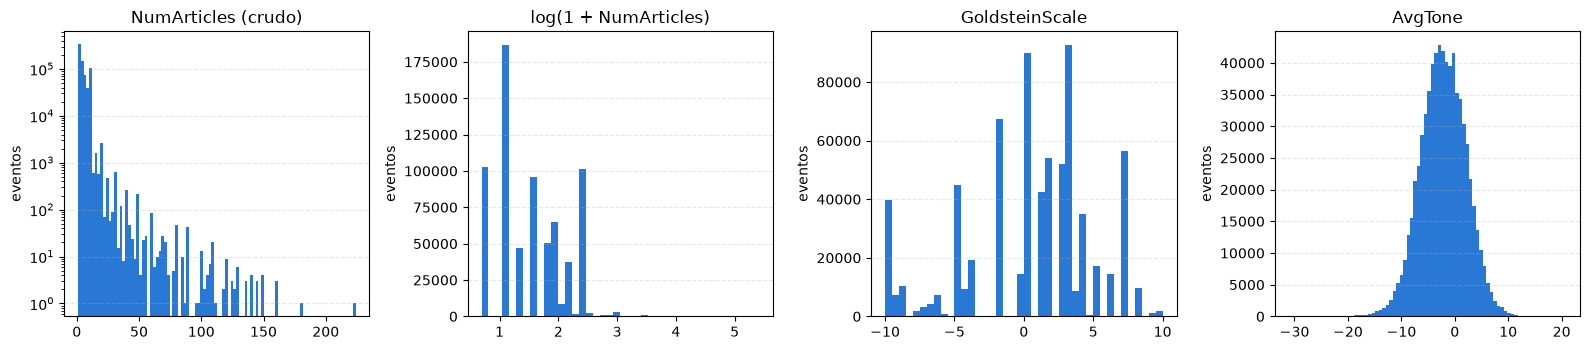

In [9]:
continuas = pd.DataFrame({
    "GoldsteinScale": eventos["GoldsteinScale"],
    "AvgTone": eventos["AvgTone"],
    "log_NumMentions": np.log1p(eventos["NumMentions"]),
    "log_NumSources": np.log1p(eventos["NumSources"]),
    "log_NumArticles": np.log1p(eventos["NumArticles"]),
    "IsRootEvent": eventos["IsRootEvent"],
})

fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
axes[0].hist(eventos["NumArticles"], bins=100, color="#2a78d6")
axes[0].set_title("NumArticles (crudo)")
axes[0].set_yscale("log")
axes[1].hist(continuas["log_NumArticles"], bins=40, color="#2a78d6")
axes[1].set_title("log(1 + NumArticles)")
axes[2].hist(eventos["GoldsteinScale"], bins=40, color="#2a78d6")
axes[2].set_title("GoldsteinScale")
axes[3].hist(eventos["AvgTone"], bins=80, color="#2a78d6")
axes[3].set_title("AvgTone")
for ax in axes:
    ax.set_ylabel("eventos")
    ax.grid(axis="y", linestyle="--", alpha=0.3)
fig.tight_layout()
plt.show()

In [10]:
X = pd.concat([continuas, dummies], axis=1)
print("Matriz de datos:", X.shape)
X.head()

Matriz de datos: (705958, 22)


,GoldsteinScale,AvgTone,log_NumMentions,log_NumSources,log_NumArticles,IsRootEvent,Actor1_GOV,Actor1_SIN_ACTOR,Actor1_SIN_ROL,Actor2_GOV,Actor2_SIN_ACTOR,Actor2_SIN_ROL,Interaccion_01,Interaccion_02,Interaccion_03,Interaccion_04,Interaccion_05,Interaccion_11,Interaccion_19,Region_IN,Region_UK,Region_US
0,8.0,-2.995539,1.386294,0.693147,1.386294,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0,1
1,7.0,-5.485893,2.397895,0.693147,2.397895,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,-10.0,1.668653,1.945910,0.693147,1.945910,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,1,0
3,-10.0,1.668653,1.609438,0.693147,1.609438,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0
4,8.0,-1.403888,2.397895,0.693147,2.397895,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0


Me queda una matriz de **~706 mil eventos × 22 variables**: 6 continuas/binarias y 16 indicadoras. Algunas cosas que se ven en los histogramas:
- `GoldsteinScale` no es continua de verdad. Toma pocos valores discretos (uno por `EventCode`) y tiene un pico en −10, que corresponde a los eventos de combate (19x).
- `AvgTone` está centrado un poco por debajo de cero (≈ −2,2); en promedio, la cobertura de noticias es levemente negativa.

### 2) Descripción Multivariante
1. **Vector de Medias:** calculen el vector de medias global y calculen un vectores de medias por país. Calculen las distancias entre todos los vectores (global vs país y país vs país).
2. **Matriz de Correlaciones:** Construyan mapas de calor e interpreten la matriz de correlación a nivel global y por país.


## 2) Descripción multivariante

### 2.1) Vectores de medias y distancias

**Vector de medias global.** Las variables de región las dejo afuera de los perfiles, porque son justamente el agrupador: el perfil de Estados Unidos tendría `Region_US = 1` por construcción y eso inflaría todas sus distancias sin decir nada del tipo de evento.

**Vectores por país.** El 5% sólo deja a US, IN y UK como categorías propias, y con tres países no alcanza para ver una "topología". Por eso, para esta parte agrupo por el país original (sin reducir) y tomo los **10 países con más eventos**, que juntos son ~61% de la muestra. La regla del 5% sigue valiendo para la matriz que entra al ACP; acá sólo cambia el agrupador.

In [11]:
PAISES = {"US": "Estados Unidos", "IN": "India", "UK": "Reino Unido", "NI": "Nigeria", "IS": "Israel",
          "RS": "Rusia", "CA": "Canadá", "AS": "Australia", "IR": "Irán", "CH": "China"}

vars_perfil = [c for c in X.columns if not c.startswith("Region_")]
media_global = X[vars_perfil].mean()

top10 = eventos["PaisFIPS"].value_counts().head(10)
print("Top 10 países (FIPS):", dict(zip(top10.index, (top10 / len(eventos)).round(3))))
assert set(top10.index) == set(PAISES), "Cambió el top 10, revisar el diccionario de nombres"

medias_pais = X[vars_perfil].groupby(eventos["PaisFIPS"]).mean().loc[top10.index]
medias_pais.index = medias_pais.index.map(PAISES)

tabla_medias = pd.concat([media_global.rename("GLOBAL"), medias_pais.T], axis=1)
tabla_medias.round(3)

Top 10 países (FIPS): {'US': 0.305, 'IN': 0.065, 'UK': 0.053, 'NI': 0.04, 'IS': 0.039, 'RS': 0.027, 'CA': 0.027, 'AS': 0.021, 'IR': 0.018, 'CH': 0.017}


,GLOBAL,Estados Unidos,India,Reino Unido,Nigeria,Israel,Rusia,Canadá,Australia,Irán,China
GoldsteinScale,0.412,0.441,-0.048,0.467,0.630,-1.128,-0.026,1.108,0.618,-0.375,1.168
AvgTone,-2.151,-2.277,-2.435,-1.678,-1.276,-4.207,-3.992,-0.748,-1.617,-3.808,-1.137
log_NumMentions,1.552,1.512,1.624,1.578,1.518,1.447,1.431,1.629,1.696,1.409,1.554
log_NumSources,0.708,0.709,0.701,0.722,0.695,0.709,0.715,0.713,0.768,0.713,0.706
log_NumArticles,1.542,1.503,1.613,1.565,1.511,1.439,1.425,1.617,1.672,1.405,1.540
IsRootEvent,0.529,0.534,0.572,0.546,0.546,0.425,0.453,0.522,0.506,0.439,0.503
Actor1_GOV,0.129,0.102,0.157,0.104,0.203,0.114,0.182,0.128,0.096,0.148,0.113
Actor1_SIN_ACTOR,0.099,0.118,0.124,0.114,0.084,0.062,0.048,0.108,0.124,0.057,0.084
Actor1_SIN_ROL,0.467,0.437,0.259,0.493,0.406,0.546,0.569,0.466,0.457,0.594,0.559
Actor2_GOV,0.089,0.071,0.108,0.070,0.143,0.084,0.119,0.082,0.058,0.108,0.086


Algunas cosas que se ven en la tabla, antes de calcular distancias:

- **Israel** tiene el tono más negativo (−4,2 contra −2,2 global), el Goldstein medio más bajo (−1,1) y la proporción de eventos de combate (`Interaccion_19`) más alta: 11,7%, casi el doble que el 6,0% global.
- **Rusia e Irán** se parecen mucho entre sí y a Israel: tono ≈ −4,0 y −3,8, Goldstein medio cerca de cero o negativo, 9–10% de combates, menos menciones por evento, menos *root events* (~44%) y muchos actores `SIN_ROL` (~57–59%, o sea, actores identificados sólo por el país).
- **Canadá y China** son los de tono menos negativo (−0,7 y −1,1) y Goldstein más alto (1,1 y 1,2), con más eventos de consulta y cooperación.
- **India** también tiene Goldstein medio levemente negativo (−0,05), pero por otro motivo: tiene pocos combates (3,3%) y más eventos de desaprobación y amenaza que caen en `OTHER`. Es el país con menos actores `SIN_ROL` (26%). **Nigeria** es el de mayor proporción de gobiernos como Actor1 (20%) y el que más declaraciones públicas (01) tiene.

**Distancias.** Las variables tienen escalas muy distintas (Goldstein va de −10 a 10 y las dummies de 0 a 1), así que no tiene sentido usar la distancia euclídea sobre las medias crudas. Calculo dos:
1. **Euclídea estandarizada**: divido cada variable por su desvío global, así las diferencias quedan expresadas en desvíos estándar.
2. **Mahalanobis** con la covarianza global, que además tiene en cuenta las correlaciones. Por ejemplo, `log_NumMentions` y `log_NumArticles` están correlacionadas casi 1, y con la euclídea esa diferencia se contaría dos veces.

In [12]:
from scipy.spatial.distance import pdist, squareform

desvio_global = X[vars_perfil].std()
Z = (medias_pais - media_global) / desvio_global          # medias por país en desvíos estándar
S_inv = np.linalg.inv(X[vars_perfil].cov().values)

dist_global = pd.DataFrame({
    "Euclídea estandarizada": np.sqrt((Z ** 2).sum(axis=1)),
    "Mahalanobis": [np.sqrt(d @ S_inv @ d) for d in (medias_pais - media_global).values],
}).sort_values("Euclídea estandarizada")

D_euc = pd.DataFrame(squareform(pdist(Z.values)), index=Z.index, columns=Z.index)
D_mah = pd.DataFrame(squareform(pdist(medias_pais.values, "mahalanobis", VI=S_inv)),
                     index=medias_pais.index, columns=medias_pais.index)

dist_global.round(3)

,Euclídea estandarizada,Mahalanobis
PaisFIPS,,
Estados Unidos,0.228,0.237
Reino Unido,0.241,0.245
Canadá,0.444,0.374
China,0.471,0.430
Nigeria,0.521,0.474
India,0.673,0.641
Australia,0.697,0.643
Irán,0.789,0.657
Rusia,0.804,0.720


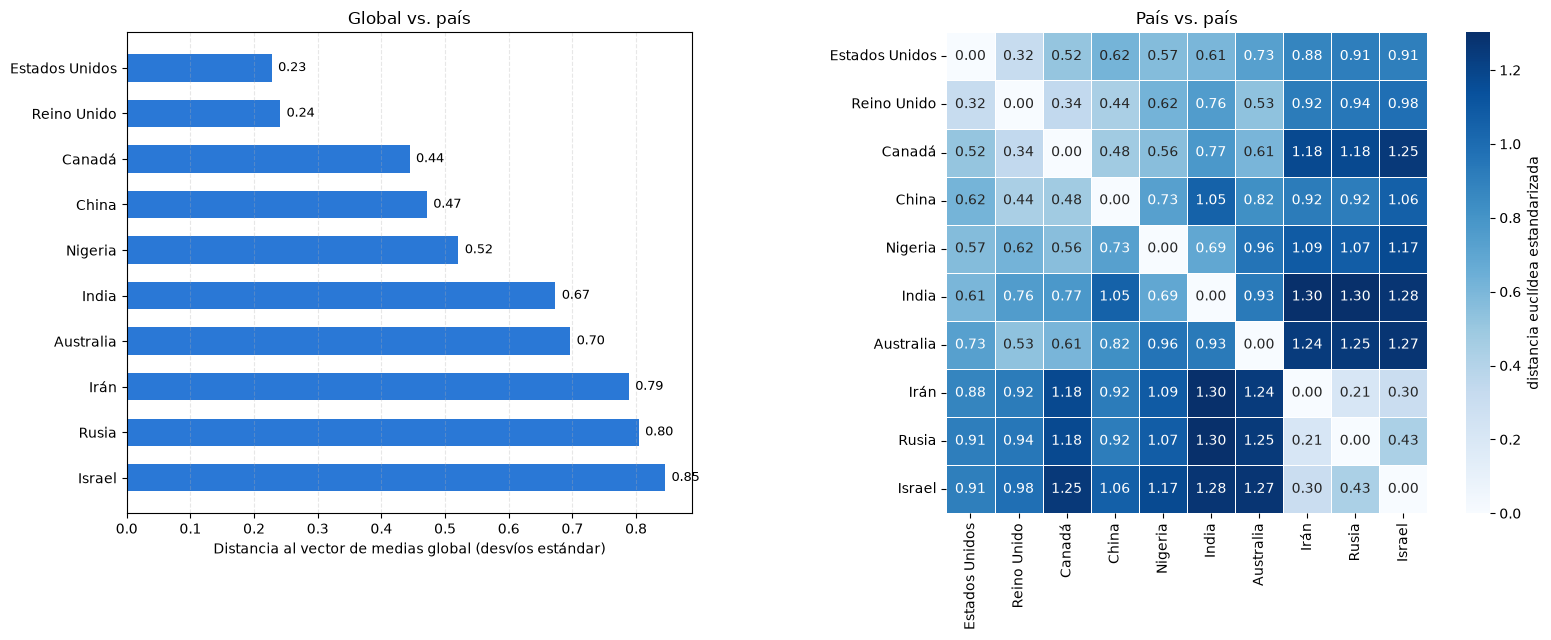

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1, 1.35]})

orden = dist_global.index
axes[0].barh(orden, dist_global["Euclídea estandarizada"], color="#2a78d6", height=0.6)
axes[0].invert_yaxis()
axes[0].set_xlabel("Distancia al vector de medias global (desvíos estándar)")
axes[0].set_title("Global vs. país")
axes[0].grid(axis="x", linestyle="--", alpha=0.3)
for i, v in enumerate(dist_global["Euclídea estandarizada"]):
    axes[0].text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=9)

sns.heatmap(D_euc.loc[orden, orden], annot=True, fmt=".2f", cmap="Blues", square=True,
            linewidths=0.5, cbar_kws={"label": "distancia euclídea estandarizada"}, ax=axes[1])
axes[1].set_title("País vs. país")
axes[1].set_xlabel("")
axes[1].set_ylabel("")
fig.tight_layout()
plt.show()

In [14]:
def pares_extremos(D, n=3):
    s = D.where(np.triu(np.ones(D.shape, dtype=bool), k=1)).stack().dropna().sort_values()
    return pd.concat([s.head(n), s.tail(n)]).rename("distancia")

print("Pares más parecidos y más distintos (euclídea estandarizada):")
print(pares_extremos(D_euc).round(3).to_string())

# ¿Las dos distancias ordenan los pares de la misma manera?
triu = np.triu_indices(len(D_euc), k=1)
rho = pd.Series(D_euc.values[triu]).corr(pd.Series(D_mah.values[triu]), method="spearman")
print(f"\nCorrelación de Spearman entre las dos distancias (45 pares): {rho:.3f}")

Pares más parecidos y más distintos (euclídea estandarizada):
PaisFIPS        PaisFIPS   
Rusia           Irán           0.210
Israel          Irán           0.301
Estados Unidos  Reino Unido    0.317
India           Israel         1.275
                Irán           1.302
                Rusia          1.302

Correlación de Spearman entre las dos distancias (45 pares): 0.986


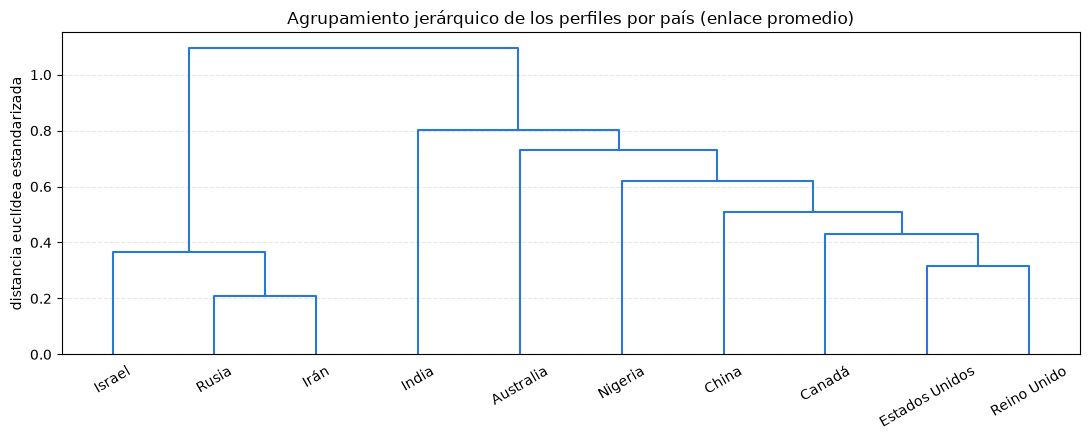

In [15]:
from scipy.cluster.hierarchy import linkage, dendrogram

fig, ax = plt.subplots(figsize=(11, 4.5))
dendrogram(linkage(Z.values, method="average", metric="euclidean"), labels=Z.index.tolist(),
           color_threshold=0, above_threshold_color="#2a78d6", leaf_rotation=30, leaf_font_size=10, ax=ax)
ax.set_ylabel("distancia euclídea estandarizada")
ax.set_title("Agrupamiento jerárquico de los perfiles por país (enlace promedio)")
ax.grid(axis="y", linestyle="--", alpha=0.3)
fig.tight_layout()
plt.show()

**¿Qué perfiles se parecen y cuáles no?**

- Las distancias son chicas en general (todas por debajo de 1,5 desvíos). Los países se diferencian en matices; ninguno tiene un perfil completamente distinto. Tiene sentido, porque el tipo de evento más común en todos lados es "consultar" o "hacer una declaración".
- **Estados Unidos** es el más cercano al vector global (0,23), pero eso es casi automático: aporta ~30% de los eventos, así que buena parte del promedio global *es* Estados Unidos. Muy cerca está el Reino Unido (0,24) y después Canadá.
- El par más parecido de todos es **Rusia–Irán** (0,21), seguido por **Israel–Irán** (0,30). Los tres países tienen el mismo tipo de cobertura: tono muy negativo, mucho combate y actores identificados sólo por el país. Después vienen **Estados Unidos–Reino Unido** (0,32) y **Reino Unido–Canadá** (0,34), es decir, la cobertura anglosajona "de agenda normal".
- Los más alejados son **India** contra **Rusia, Irán e Israel** (≈ 1,3). India tiene muchos actores con rol explícito, más menciones por evento y pocos combates; esos tres países, lo contrario.
- En el dendrograma se ven dos grupos: **{Rusia, Irán, Israel}**, el bloque de **conflicto** (tono más negativo y más eventos tipo 19), y el resto. Dentro del resto, Estados Unidos, Reino Unido y Canadá forman el núcleo más compacto, e India y Australia son los que se unen más tarde.
- Mahalanobis y la euclídea estandarizada dan prácticamente el mismo orden (Spearman ≈ 0,986), así que las conclusiones no dependen de cuál use. Mahalanobis da valores un poco menores porque no cuenta dos veces la diferencia en menciones/artículos.

### 2.2) Matriz de correlaciones

Primero la matriz global sobre las 22 variables. Después la comparo por país. Dentro de un país las dummies de región son constantes, así que para esas matrices uso sólo `vars_perfil`.

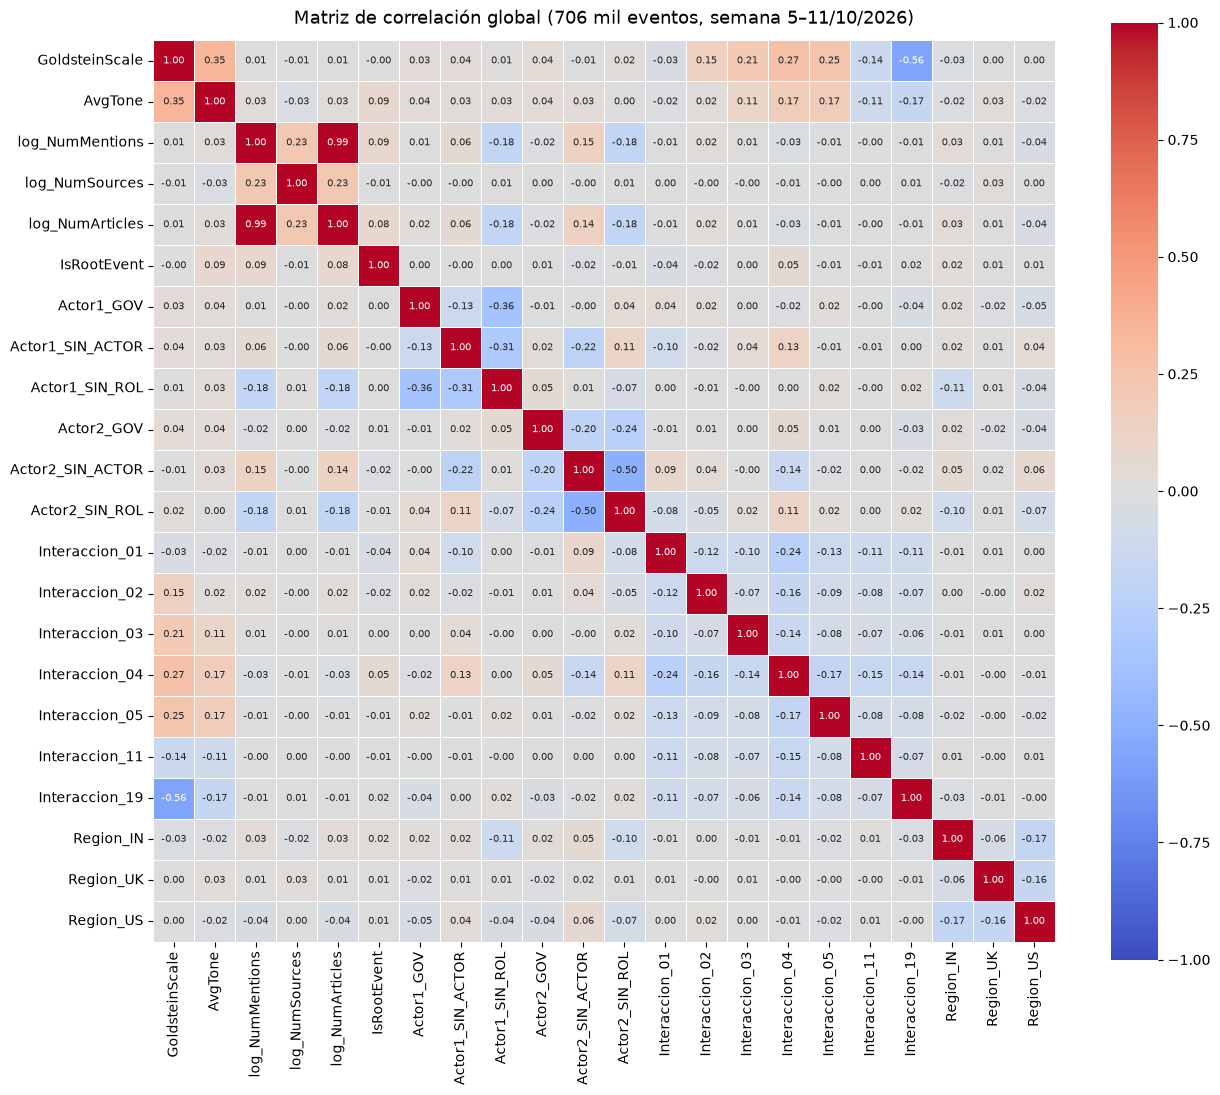

In [16]:
corr_global = X.corr()

plt.figure(figsize=(13, 11))
sns.heatmap(corr_global, annot=True, fmt=".2f", annot_kws={"size": 7}, cmap="coolwarm",
            vmin=-1, vmax=1, center=0, square=True, linewidths=0.5)
plt.title("Matriz de correlación global (706 mil eventos, semana 5–11/10/2026)", fontsize=13, pad=12)
plt.tight_layout()
plt.show()

**Lectura de la matriz global:**

- **`log_NumMentions` y `log_NumArticles` (r = 0,99)**: son prácticamente la misma variable. Casi siempre cada artículo menciona el evento una sola vez, así que contar menciones o artículos da lo mismo. Esto ya anticipa que el ACP va a juntarlas en una sola componente. `log_NumSources` se asocia bastante menos con ellas (0,23): muchos artículos no implican muchos medios distintos, porque la mayoría de los eventos tiene una sola fuente.
- **`GoldsteinScale` y `AvgTone` (r = 0,35)**: hay una asociación positiva moderada. Los eventos que CAMEO clasifica como más cooperativos se cuentan con un tono más positivo. No es más alta porque Goldstein es un puntaje fijo por tipo de evento y el tono depende del artículo puntual.
- **`GoldsteinScale` y `Interaccion_19` (r = −0,56)**: es la asociación más fuerte entre una continua y una dummy, y es esperable, porque los combates tienen Goldstein −10. Las categorías cooperativas (03, 04, 05) correlacionan positivo con Goldstein y con el tono.
- **Bloques negativos entre dummies de la misma variable** (por ejemplo, `Actor2_SIN_ACTOR` con `Actor2_SIN_ROL`, −0,50): salen de la construcción misma, porque si un evento está en una categoría no puede estar en otra. No las interpreto como una relación real.
- **Actores y cobertura**: los eventos sin Actor2 tienen algo más de menciones (+0,15) y los de actores `SIN_ROL` algo menos (−0,18). El resto de las correlaciones están cerca de cero. Con 706 mil observaciones casi todo es "estadísticamente significativo", así que conviene mirar la magnitud, no el p-valor.

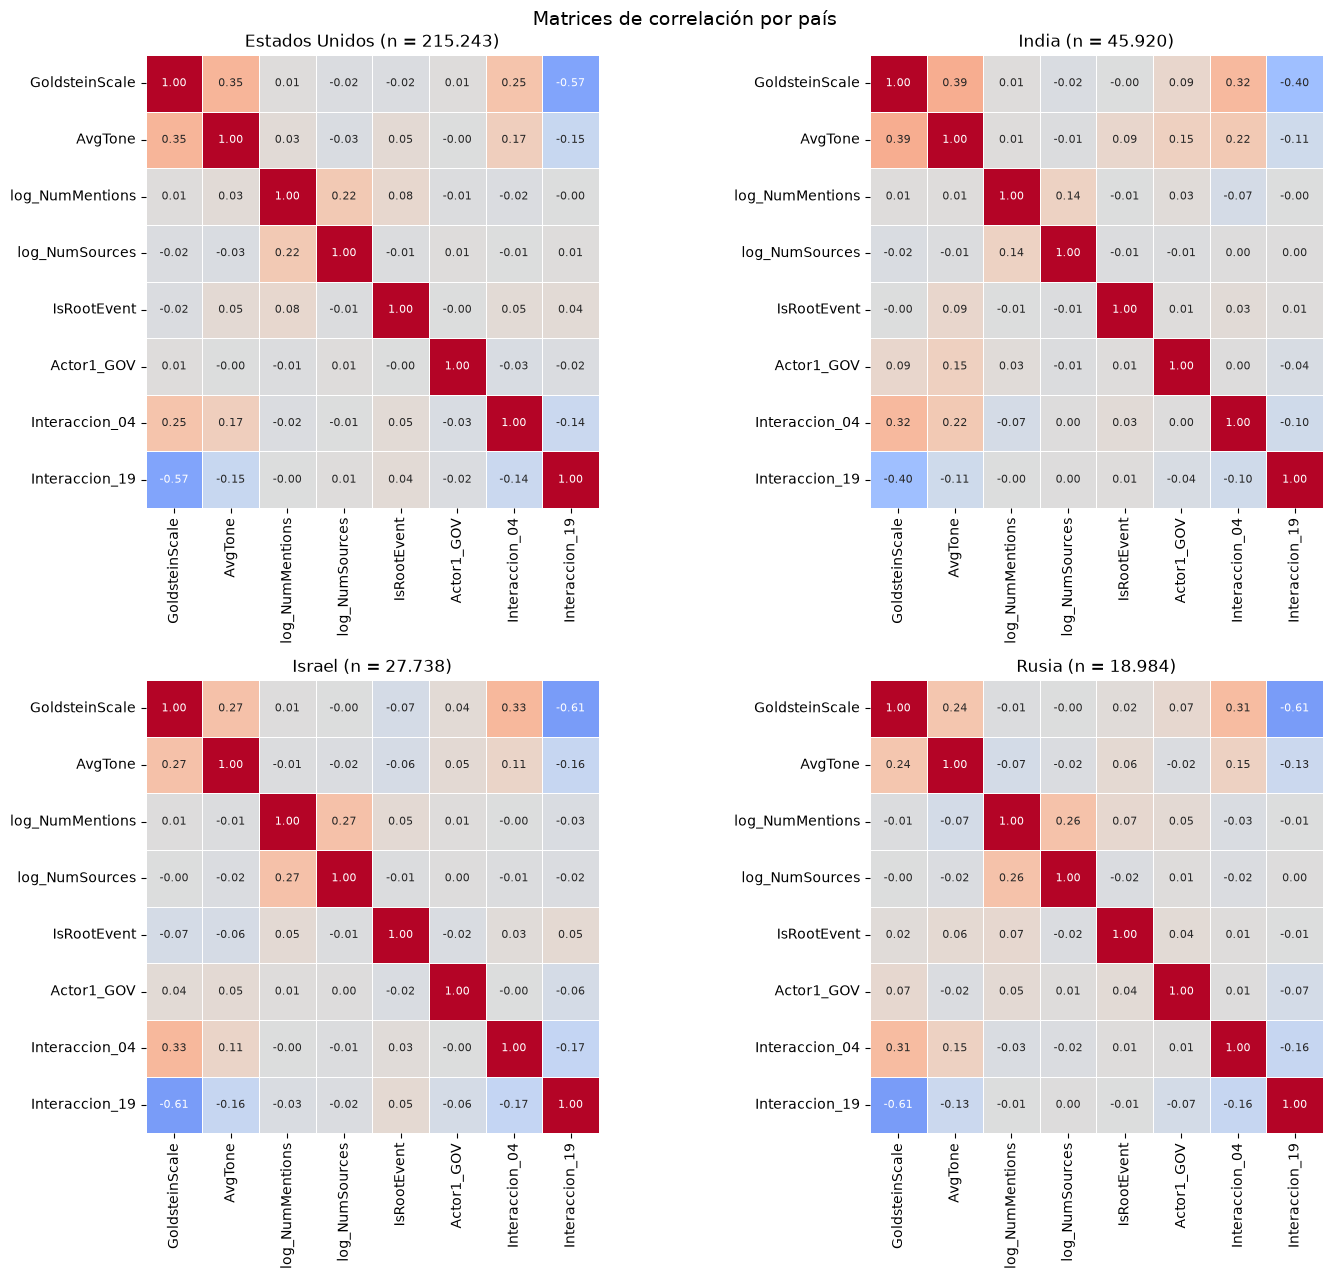

In [17]:
# Correlaciones por país: mapas de calor de los 4 países con más eventos (variables continuas + interacción)
vars_corr_pais = ["GoldsteinScale", "AvgTone", "log_NumMentions", "log_NumSources", "IsRootEvent",
                  "Actor1_GOV", "Interaccion_04", "Interaccion_19"]
paises_mapa = ["US", "IN", "IS", "RS"]

fig, axes = plt.subplots(2, 2, figsize=(15, 13))
for ax, p in zip(axes.flat, paises_mapa):
    Cp = X.loc[(eventos["PaisFIPS"] == p).values, vars_corr_pais].corr()
    sns.heatmap(Cp, annot=True, fmt=".2f", annot_kws={"size": 8}, cmap="coolwarm", vmin=-1, vmax=1,
                center=0, square=True, linewidths=0.5, cbar=False, ax=ax)
    ax.set_title(f"{PAISES[p]} (n = {(eventos['PaisFIPS'] == p).sum():,})".replace(",", "."))
fig.suptitle("Matrices de correlación por país", fontsize=14)
fig.tight_layout()
plt.show()

In [18]:
# Para comparar los 10 países a la vez, resumo algunos pares de variables en una tabla
pares = [("GoldsteinScale", "AvgTone"), ("log_NumMentions", "log_NumArticles"),
         ("log_NumSources", "log_NumArticles"), ("GoldsteinScale", "Interaccion_19"),
         ("AvgTone", "Interaccion_19"), ("AvgTone", "IsRootEvent")]

comparacion = {"GLOBAL": [corr_global.loc[a, b] for a, b in pares]}
for p in top10.index:
    Cp = X.loc[(eventos["PaisFIPS"] == p).values, vars_perfil].corr()
    comparacion[PAISES[p]] = [Cp.loc[a, b] for a, b in pares]

tabla_corr = pd.DataFrame(comparacion, index=[f"{a} ~ {b}" for a, b in pares])
tabla_corr.round(2)

,GLOBAL,Estados Unidos,India,Reino Unido,Nigeria,Israel,Rusia,Canadá,Australia,Irán,China
GoldsteinScale ~ AvgTone,0.35,0.35,0.39,0.30,0.32,0.27,0.24,0.30,0.33,0.25,0.25
log_NumMentions ~ log_NumArticles,0.99,0.99,0.99,0.99,0.99,0.99,1.00,0.99,0.98,1.00,0.99
log_NumSources ~ log_NumArticles,0.23,0.22,0.14,0.36,0.08,0.27,0.26,0.27,0.51,0.24,0.20
GoldsteinScale ~ Interaccion_19,-0.56,-0.57,-0.40,-0.52,-0.53,-0.61,-0.61,-0.53,-0.54,-0.63,-0.44
AvgTone ~ Interaccion_19,-0.17,-0.15,-0.11,-0.10,-0.20,-0.16,-0.13,-0.13,-0.14,-0.16,-0.07
AvgTone ~ IsRootEvent,0.09,0.05,0.09,0.13,0.05,-0.06,0.06,0.05,0.11,0.01,0.11


**Comparación entre países:**

- La estructura de correlación es bastante **parecida en todos los países**: los mismos signos y órdenes de magnitud que en la global. Las relaciones vienen más de cómo GDELT codifica los eventos que del país donde ocurren.
- Goldstein–tono varía entre 0,24 (Rusia) y 0,39 (India). En el bloque de conflicto (Rusia, Irán, Israel: 0,24–0,27) el vínculo es más débil: hay eventos cooperativos (reuniones, negociaciones) que igual se cuentan en tono negativo porque el contexto general es de conflicto.
- La asociación Goldstein–combate es más fuerte en Irán (−0,63), Israel y Rusia (−0,61), donde los eventos 19 son más frecuentes y pesan más en la varianza de Goldstein. En India es la más débil (−0,40), justamente porque casi no hay combates.
- Lo que más cambia entre países es la relación fuentes–artículos: va de 0,08 en Nigeria a 0,51 en Australia. En Nigeria, si un evento tiene muchos artículos casi siempre es porque un mismo medio publica varias notas. En Australia es más común que lo levanten varios medios distintos.
- En Israel la correlación tono–*root event* es levemente negativa (−0,06) y en Irán es prácticamente nula (0,01), mientras que en el resto es positiva. Ahí los eventos "principales" de la noticia suelen ser los negativos.

### 3) Reducción de Dimensionalidad e Interpretación de Componentes

1. **Ajuste del Modelo:** Apliquen la técnica de Análisis por Componentes Principales (ACP) sobre la matriz de datos con las características escaladas.
2. **Análisis de Varianza Explicada:** Generen el gráfico de sedimentación (Scree Plot) y determinen la cantidad mínima de componentes principales requeridas.
3. **Interpretación de Componentes:** Analicen e interpreten los vectores de carga (loadings) de las componentes principales elegidas. Asignen un nombre o dimensión conceptual a cada una según las variables con mayor peso relativo.
4. **Visualización Biplot:** Proyecten las observaciones en el plano de las dos primeras componentes principales (PC1 vs. PC2). Identifiquen patrones de agrupamiento o presencia de valores atípicos (outliers) multivariantes.

## 3) Reducción de dimensionalidad: ACP

### 3.1) Ajuste del modelo

Estandarizo las 22 columnas con `StandardScaler` (z-score) y ajusto el ACP, igual que en clase con Iris y Wine. Estandarizar equivale a hacer el ACP sobre la matriz de correlación. Sin esto, Goldstein (varianza ≈ 20) se llevaría casi toda la primera componente sólo por su escala.

In [19]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X_std = StandardScaler().fit_transform(X)
pca = PCA()
scores = pca.fit_transform(X_std)

autovalores = pca.explained_variance_
var_exp = pca.explained_variance_ratio_
var_acum = np.cumsum(var_exp)
loadings = pd.DataFrame(pca.components_.T * np.sqrt(autovalores), index=X.columns,
                        columns=[f"PC{i + 1}" for i in range(len(autovalores))])

pd.DataFrame({"autovalor": autovalores, "% varianza": 100 * var_exp, "% acumulado": 100 * var_acum},
             index=loadings.columns).round(2).T

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,PC16,PC17,PC18,PC19,PC20,PC21,PC22
autovalor,2.29,2.03,1.71,1.38,1.23,1.22,1.15,1.12,1.10,1.08,1.07,1.03,1.00,0.96,0.85,0.75,0.65,0.44,0.37,0.32,0.23,0.01
% varianza,10.41,9.24,7.78,6.26,5.59,5.55,5.24,5.08,4.98,4.92,4.87,4.67,4.54,4.38,3.89,3.41,2.97,2.00,1.67,1.48,1.04,0.03
% acumulado,10.41,19.65,27.42,33.68,39.27,44.83,50.07,55.15,60.13,65.06,69.93,74.60,79.13,83.51,87.40,90.81,93.79,95.78,97.45,98.93,99.97,100.00


### 3.2) Varianza explicada y scree plot

Hago dos gráficos separados en lugar de uno con doble eje, para que no se confundan las escalas: a la izquierda los autovalores (con la línea de Kaiser en 1) y a la derecha el porcentaje acumulado.

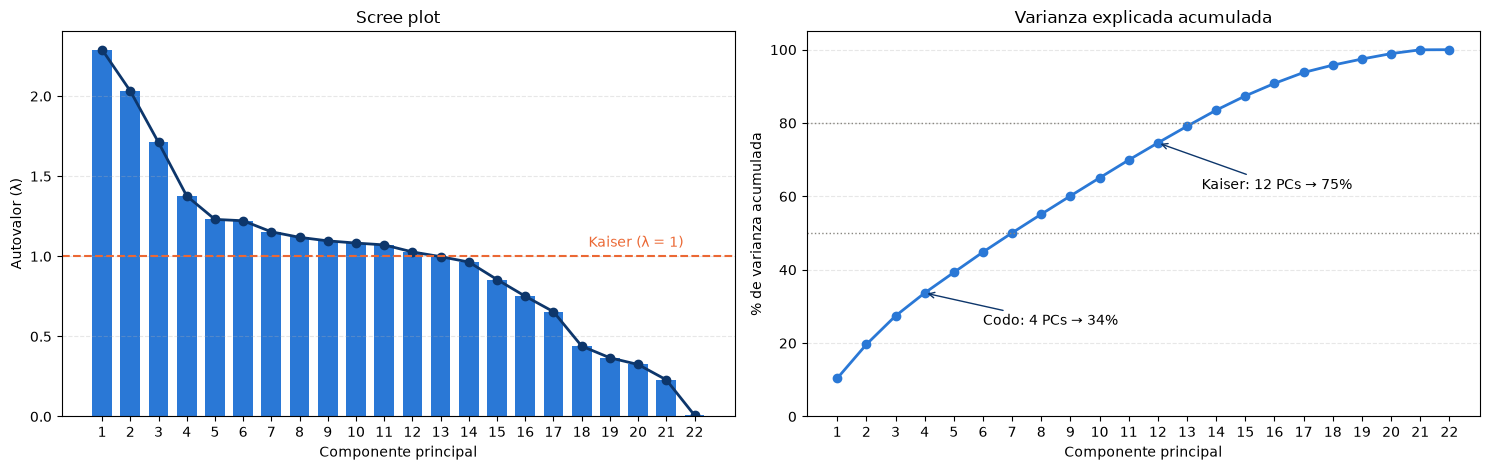

In [20]:
k_kaiser = int((autovalores > 1).sum())
pcs = np.arange(1, len(autovalores) + 1)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
axes[0].bar(pcs, autovalores, color="#2a78d6", width=0.7)
axes[0].plot(pcs, autovalores, color="#0d366b", marker="o", linewidth=2, markersize=6)
axes[0].axhline(1, color="#eb6834", linestyle="--", linewidth=1.5)
axes[0].text(len(pcs) - 0.4, 1.06, "Kaiser (λ = 1)", color="#eb6834", ha="right")
axes[0].set_xlabel("Componente principal")
axes[0].set_ylabel("Autovalor (λ)")
axes[0].set_title("Scree plot")
axes[0].set_xticks(pcs)

axes[1].plot(pcs, 100 * var_acum, color="#2a78d6", marker="o", linewidth=2, markersize=6)
for nivel in (50, 80):
    axes[1].axhline(nivel, color="#898781", linestyle=":", linewidth=1)
axes[1].annotate(f"Kaiser: {k_kaiser} PCs → {100 * var_acum[k_kaiser - 1]:.0f}%",
                 xy=(k_kaiser, 100 * var_acum[k_kaiser - 1]), xytext=(k_kaiser + 1.5, 62),
                 arrowprops={"arrowstyle": "->", "color": "#0d366b"})
axes[1].annotate(f"Codo: 4 PCs → {100 * var_acum[3]:.0f}%", xy=(4, 100 * var_acum[3]),
                 xytext=(6, 25), arrowprops={"arrowstyle": "->", "color": "#0d366b"})
axes[1].set_xlabel("Componente principal")
axes[1].set_ylabel("% de varianza acumulada")
axes[1].set_title("Varianza explicada acumulada")
axes[1].set_xticks(pcs)
axes[1].set_ylim(0, 105)
for ax in axes:
    ax.grid(axis="y", linestyle="--", alpha=0.3)
fig.tight_layout()
plt.show()

**¿Cuántas componentes?**

Acá los criterios no coinciden, y la diferencia es parte de la respuesta:

- **Kaiser** (λ > 1) deja **12 componentes**, que explican ~75% de la varianza. En Iris o Wine con 2 alcanzaba; acá hacen falta 12 de 22 (y la 13 queda apenas por debajo, con λ = 0,998).
- El **scree plot** tiene un codo claro en la **cuarta componente**. Las primeras cuatro tienen autovalores de 2,3, 2,0, 1,7 y 1,4. De la 5 a la 12 los autovalores quedan todos en una meseta entre 1,03 y 1,23.

Me quedo con **4 componentes (~34% de la varianza)** para interpretar. Una componente con λ ≈ 1 explica lo mismo que una sola variable original estandarizada, así que en la práctica no resume nada. Si miro las cargas de PC5 a PC12, cada una está dominada por una o dos dummies sueltas (una categoría de interacción, una región). Las cuento como ruido de la codificación más que como estructura compartida. El último autovalor (≈ 0,008) es prácticamente cero y corresponde a la redundancia `log_NumMentions` ≈ `log_NumArticles`.

En términos de la pregunta de investigación: **el ecosistema de noticias de GDELT es poco compresible**. Hay unos pocos ejes con estructura, pero la mayor parte de la varianza está repartida en variables casi independientes entre sí, que es justamente lo que decía la introducción sobre datos ruidosos, dispersos y de alta dimensión. Si hiciera falta conservar el 80% de la información para un modelo posterior, habría que quedarse con 14 componentes, y la reducción frente a las 22 variables originales sería chica.

### 3.3) Interpretación de las cargas (loadings)

Uso como cargas los autovectores multiplicados por √λ, como en clase. Así cada carga es la correlación entre la variable y la componente.

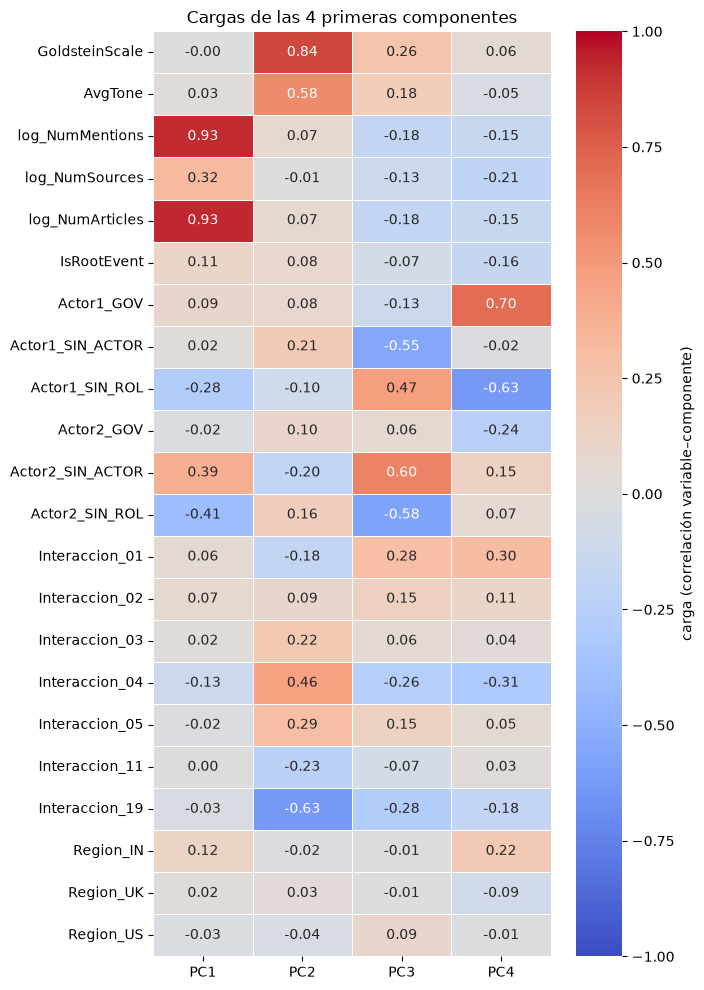

PC1: log_NumArticles (+0.93), log_NumMentions (+0.93), Actor2_SIN_ROL (-0.41), Actor2_SIN_ACTOR (+0.39), log_NumSources (+0.32)
PC2: GoldsteinScale (+0.84), Interaccion_19 (-0.63), AvgTone (+0.58), Interaccion_04 (+0.46), Interaccion_05 (+0.29)
PC3: Actor2_SIN_ACTOR (+0.60), Actor2_SIN_ROL (-0.58), Actor1_SIN_ACTOR (-0.55), Actor1_SIN_ROL (+0.47), Interaccion_01 (+0.28)
PC4: Actor1_GOV (+0.70), Actor1_SIN_ROL (-0.63), Interaccion_04 (-0.31), Interaccion_01 (+0.30), Actor2_GOV (-0.24)


In [21]:
K = 4
plt.figure(figsize=(7, 10))
sns.heatmap(loadings.iloc[:, :K], annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0,
            linewidths=0.5, cbar_kws={"label": "carga (correlación variable–componente)"})
plt.title("Cargas de las 4 primeras componentes")
plt.tight_layout()
plt.show()

for pc in loadings.columns[:K]:
    col = loadings[pc]
    top = col.reindex(col.abs().sort_values(ascending=False).index).head(5)
    print(f"{pc}: " + ", ".join(f"{v} ({c:+.2f})" for v, c in top.items()))

| PC | % var. | Variables con más peso | Nombre que le doy |
|---|---|---|---|
| **PC1** | 10,4% | `log_NumMentions` (+0,93), `log_NumArticles` (+0,93), `Actor2_SIN_ROL` (−0,41), `Actor2_SIN_ACTOR` (+0,39) | **Volumen de cobertura.** Separa los eventos de los que se habló mucho de los que tuvieron una sola nota. Del lado positivo también quedan los eventos sin Actor2 (declaraciones unilaterales, que se repiten en muchos artículos). |
| **PC2** | 9,2% | `GoldsteinScale` (+0,84), `Interaccion_19` (−0,63), `AvgTone` (+0,58), `Interaccion_04` (+0,46) | **Cooperación ↔ conflicto.** Del lado positivo están las consultas y la cooperación diplomática con tono positivo; del negativo, los combates con tono negativo. Es la componente más fácil de nombrar y tiene sentido que junte Goldstein y tono, que eran las dos continuas correlacionadas. |
| **PC3** | 7,8% | `Actor2_SIN_ACTOR` (+0,60), `Actor2_SIN_ROL` (−0,58), `Actor1_SIN_ACTOR` (−0,55), `Actor1_SIN_ROL` (+0,47) | **Estructura de la díada (qué actor falta).** En el polo positivo están los eventos con un único actor, identificado sólo por país y sin receptor. En el negativo, los eventos a los que les falta el iniciador. Habla más de cómo GDELT pudo extraer los actores de la nota que de la noticia en sí. |
| **PC4** | 6,3% | `Actor1_GOV` (+0,70), `Actor1_SIN_ROL` (−0,63), `Interaccion_04` (−0,31), `Interaccion_01` (+0,30) | **Protagonismo gubernamental.** Distingue los eventos iniciados por un gobierno (que suelen ser declaraciones públicas) de los iniciados por un actor-país sin rol. |

Algo que me llamó la atención: **la región casi no aparece en las primeras cuatro componentes** (ninguna carga de `Region_US`, `Region_IN` o `Region_UK` supera 0,25 en valor absoluto). Recién en PC5 la región domina (`Region_US` +0,66 contra `Region_IN` −0,57), pero esa componente ya está en la meseta, con λ ≈ 1,2. Lo que más diferencia a un evento de otro es cuánto se cubrió y si es cooperativo o conflictivo, no el país donde pasó. Esto coincide con la sección 2, donde las distancias entre países resultaron chicas.

### 3.4) Biplot PC1 vs. PC2

Con 706 mil puntos el gráfico se vuelve una mancha, así que dibujo una muestra aleatoria de 15 mil eventos, coloreados por `QuadClass` (que **no** entró al ACP; la uso sólo para ver si la componente de conflicto se corresponde con la clasificación CAMEO). Los outliers, en cambio, los busco sobre **todos** los eventos.

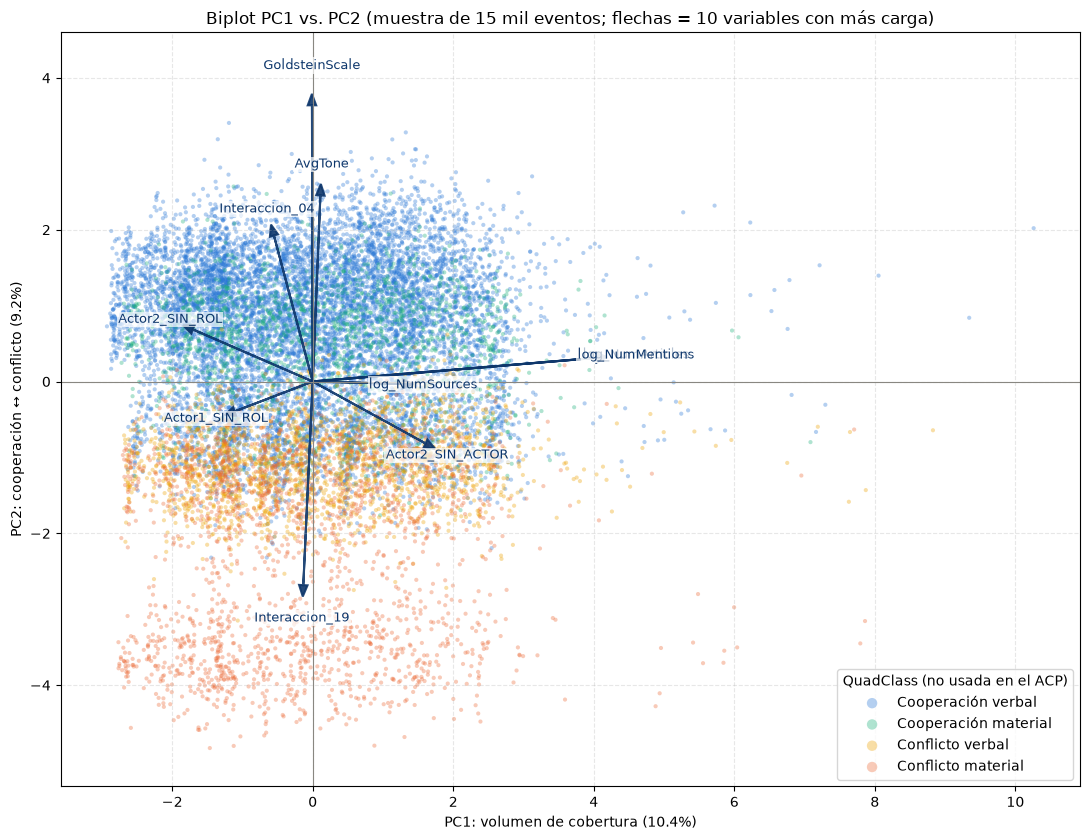

In [22]:
QUAD = {1: "Cooperación verbal", 2: "Cooperación material", 3: "Conflicto verbal", 4: "Conflicto material"}
COLORES_QUAD = {1: "#2a78d6", 2: "#1baf7a", 3: "#eda100", 4: "#eb6834"}

rng = np.random.default_rng(42)
muestra = rng.choice(len(scores), size=15_000, replace=False)
jitter = rng.normal(0, 0.04, size=(len(muestra), 2))  # Goldstein es discreto: un poco de ruido evita que se pisen los puntos

fig, ax = plt.subplots(figsize=(11, 8.5))
for q, nombre in QUAD.items():
    m = (eventos["QuadClass"].values[muestra] == q)
    ax.scatter(scores[muestra][m, 0] + jitter[m, 0], scores[muestra][m, 1] + jitter[m, 1],
               s=9, alpha=0.35, color=COLORES_QUAD[q], edgecolors="none", label=nombre)

escala = 4.5
mostrar = loadings.iloc[:, :2].pow(2).sum(axis=1).sort_values(ascending=False).head(10).index
for var in mostrar:
    x, y = loadings.loc[var, "PC1"] * escala, loadings.loc[var, "PC2"] * escala
    ax.arrow(0, 0, x, y, color="#0d366b", alpha=0.9, head_width=0.12, head_length=0.15, linewidth=1.5,
             length_includes_head=True)
    ax.text(x * 1.1, y * 1.1, var, color="#0d366b", fontsize=9, ha="center", va="center",
            bbox={"facecolor": "white", "alpha": 0.7, "edgecolor": "none", "pad": 1})

ax.set_ylim(scores[muestra, 1].min() - 0.5, 4.6)
ax.axhline(0, color="#898781", linewidth=0.8)
ax.axvline(0, color="#898781", linewidth=0.8)
ax.set_xlabel(f"PC1: volumen de cobertura ({100 * var_exp[0]:.1f}%)")
ax.set_ylabel(f"PC2: cooperación ↔ conflicto ({100 * var_exp[1]:.1f}%)")
ax.set_title("Biplot PC1 vs. PC2 (muestra de 15 mil eventos; flechas = 10 variables con más carga)")
ax.legend(title="QuadClass (no usada en el ACP)", markerscale=2.5, loc="lower right")
ax.grid(linestyle="--", alpha=0.3)
fig.tight_layout()
plt.show()

In [23]:
# Outliers multivariantes en el plano PC1–PC2: distancia de Mahalanobis sobre los scores
# (cada score dividido por su desvío, √λ). Uso como umbral el percentil 99,9 de una chi-cuadrado con 2 g.l.
from scipy.stats import chi2

d2 = (scores[:, 0] ** 2 / autovalores[0]) + (scores[:, 1] ** 2 / autovalores[1])
umbral = chi2.ppf(0.999, df=2)
es_outlier = d2 > umbral
print(f"Umbral d² = {umbral:.2f}  →  {es_outlier.sum():,} eventos atípicos ({es_outlier.mean():.2%}); "
      f"bajo normalidad esperaríamos 0,10%".replace(",", "."))
print(f"Atípicos por PC1 alto (> 0): {(es_outlier & (scores[:, 0] > 0)).sum():,}  |  "
      f"con PC2 < 0: {(es_outlier & (scores[:, 1] < 0)).sum():,}".replace(",", "."))

cols_ver = ["GlobalEventID", "Actor1Name", "Actor2Name", "EventCode", "NumMentions", "NumSources",
            "NumArticles", "AvgTone", "GoldsteinScale", "ActionGeo_FullName"]
top_out = df.iloc[np.argsort(-d2)[:10]][cols_ver].assign(PC1=scores[np.argsort(-d2)[:10], 0].round(2),
                                                        PC2=scores[np.argsort(-d2)[:10], 1].round(2))
top_out

Umbral d² = 13.82  →  1.954 eventos atípicos (0.28%); bajo normalidad esperaríamos 0.10%
Atípicos por PC1 alto (> 0): 1.932  |  con PC2 < 0: 1.076


,GlobalEventID,Actor1Name,Actor2Name,EventCode,NumMentions,NumSources,NumArticles,AvgTone,GoldsteinScale,ActionGeo_FullName,PC1,PC2
698376,1327426185,ASYLUM SEEKER,NaN,120,160,16,160,-4.325700,-4.0,"Doncaster, Doncaster, United Kingdom",12.14,-0.64
372599,1326889669,RUSSIA,NaN,190,150,15,150,-5.227273,-10.0,"Pryluky, Zhytomyrs'ka Oblast', Ukraine",11.52,-3.49
402498,1326942416,JUDGE,POLICE,112,180,18,180,-0.905797,-2.0,"Sandringham, Norfolk, United Kingdom",12.06,-0.39
376218,1326896938,NaN,POLICE,180,160,16,160,-6.015038,-9.0,"Glasgow City, Glasgow City, United Kingdom",11.77,-0.54
376217,1326896937,NaN,POLICE,173,160,16,160,-6.015038,-5.0,"Glasgow City, Glasgow City, United Kingdom",11.77,-0.03
466968,1327040949,DEFENCE SECRETARY,MILITARY,186,136,17,136,-4.094293,-10.0,Afghanistan,11.62,-0.93
347153,1326849370,POLICE,NaN,090,140,14,140,-4.804473,-2.0,"Buckingham Palace, Westminster, United Kingdom",11.62,-0.45
402489,1326942407,JUDGE,NaN,050,108,18,108,-0.905797,3.5,"Sandringham, Norfolk, United Kingdom",11.50,1.30
566551,1327203730,MINIST,NaN,013,120,12,120,-0.656455,0.4,Ireland,11.41,0.08
398429,1326935407,BARI,NaN,015,108,18,108,-6.046144,0.0,"Southwark, Southwark, United Kingdom",11.27,-0.85


**¿Qué se ve en el biplot?**

- La flecha de `log_NumArticles` no se ve porque queda exactamente debajo de la de `log_NumMentions` (r = 0,99).
- **No hay grupos separados**, sino una nube continua. Lo que sí hay es un **gradiente vertical** muy limpio por `QuadClass`: la cooperación verbal y material queda arriba y el conflicto material abajo. Eso confirma que PC2 recupera la dimensión cooperación/conflicto de CAMEO, aunque `QuadClass` no se usó para construirla.
- Los puntos forman **franjas**, sobre todo verticales en la parte de abajo. Se debe a que las variables de origen son discretas: los conteos de menciones toman pocos valores y Goldstein tiene un único valor por `EventCode`, así que muchos eventos caen exactamente en el mismo lugar (por eso agregué un poco de *jitter*).
- En PC1 la nube es **muy asimétrica hacia la derecha**: la gran mayoría de los eventos tiene una o dos notas y unos pocos tienen decenas. Es la cola larga que vimos en los histogramas, que persiste aunque se haya aplicado el logaritmo.
- **Outliers**: ~0,28% de los eventos supera el umbral del 99,9%, casi el triple de lo que esperaríamos si los scores fueran normales (no lo son, por la asimetría). Casi todos son atípicos por **volumen de cobertura** (PC1 muy alto). Mirando los diez más extremos, son eventos de 100 a 180 menciones en 12 a 18 medios distintos. Varios comparten exactamente el mismo `AvgTone`, lo que indica que salieron **del mismo artículo o de la misma noticia sindicada**: por ejemplo, dos eventos con la policía británica como Actor2 (códigos 173 y 180) tienen 160 menciones y tono −6,02, y dos eventos de un juez en el Reino Unido comparten tono −0,91. Son las grandes noticias de la semana, que GDELT parte en varios eventos (una declaración, una detención, un ataque) cada uno con la cobertura completa. Además, más de la mitad de los atípicos (1.076 de 1.954) tiene PC2 negativo, o sea que en esta semana **las noticias más cubiertas fueron sobre todo de conflicto**: por ejemplo, un evento 190 (*use conventional military force*) de Rusia en Ucrania con 150 menciones en 15 medios.
- Desde el lado del medio, estos outliers no son errores que haya que eliminar, porque son justamente las noticias que más interesan editorialmente. Para un modelo posterior sí convendría tenerlos en cuenta, porque al ser el mismo hecho repetido varias veces pueden sobrerrepresentarlo.

## Conclusiones

Vuelvo a las cuatro preguntas del enunciado:

1. **Perfil multivariante (vectores de medias).** El evento "típico" de GDELT en la semana es una consulta o una declaración, con tono levemente negativo (≈ −2,2), Goldstein apenas positivo (≈ 0,4), unas 4–5 menciones y casi siempre una sola fuente. Entre países los perfiles se diferencian en matices: Israel es el más negativo y con más combate, Rusia e Irán tienen un perfil muy parecido al de Israel (con actores sin rol y menos cobertura por evento), y Canadá y China son los más cooperativos.
2. **Topología de la cobertura (distancias).** Rusia–Irán es el par más parecido, seguido por Israel–Irán, Estados Unidos–Reino Unido y Reino Unido–Canadá. El dendrograma separa un bloque de **conflicto** {Rusia, Irán, Israel} del resto. Los más distintos son India frente a ese bloque. Euclídea estandarizada y Mahalanobis llegan a las mismas conclusiones.
3. **Estructura de correlación.** Hay pocas asociaciones fuertes: menciones ≈ artículos (redundantes), Goldstein con tono (moderada, ≈ 0,35) y Goldstein con eventos de combate (−0,56). El resto está cerca de cero. La estructura se repite en todos los países con pequeñas variaciones, lo que sugiere que viene de la codificación CAMEO más que de la geografía.
4. **Compresión (ACP).** Con 4 componentes se explica sólo ~34% de la varianza (Kaiser pediría 12 para ~75%). Las cuatro componentes interpretables son **volumen de cobertura**, **cooperación ↔ conflicto**, **estructura de la díada de actores** y **protagonismo gubernamental**. El resto es varianza repartida en dummies casi independientes. A diferencia de Iris, no hay forma de resumir GDELT en dos dimensiones sin perder la mayor parte de la información.

**Limitaciones.** Es una sola semana de datos. La regla del 5% deja la región muy pobre (sólo US, IN y UK), y el ACP sobre variables dummy estandarizadas es una aproximación: para datos mixtos sería más apropiado un análisis factorial de datos mixtos (FAMD) o un análisis de correspondencias múltiples. Lo dejo como posible extensión.

In [24]:
con.close()

---

*Formato de entrega:* Notebook con el nombre "TP3" dentro de su repositorio Github. En esta actividad deben pegar la URL con el acceso a la notebook.